# Exercise4_Oracle_Valuation_UPDATE

**OCI/AI monetisation base case | USD millions except shares, per-share values, and percentages | 1 October 2026**

This is a DCF workpaper, not a precise target price. It models Oracle’s OCI/AI data-centre capacity and utilisation as the company-specific driver: a high investment period creates early negative FCFF and additional borrowing, followed by an assumption-sensitive FY2031 cash-flow outcome.

The opening year is FY2026, ended 31 May 2026. All source facts are drawn visibly from the cached SEC Company Facts dataset where available; filing-only inputs are identified separately.

## AI risk and verification

AI helped with notebook structure, extraction organisation, and code. I independently verified the SEC Company Facts and Oracle FY2026 10-K figures used in the model. I specifically rejected the earlier WRDS `trfd` beta approach after verifying that it is an adjustment factor, not a daily-return series, and replaced it with beta calculated from saved WRDS Compustat Security Daily `prccd` returns.

## Oracle-specific driver

The company-specific driver is OCI/AI data-centre capacity and utilisation, unlike the ABG template; it is implemented through Oracle-specific high capex/revenue, PP&E-linked D&A, utilisation-driven margin expansion, and the possibility of early negative FCFF/additional borrowing.

In [1]:
from pathlib import Path
from copy import deepcopy
from datetime import date
import json
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'exercise4').exists(): ROOT = ROOT.parent
OUT, CACHE = ROOT / 'exercise4', ROOT / 'lab6' / 'cache'
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
assert (CACHE / 'CIK0001341439_companyfacts.json').exists(), 'SEC Company Facts cache is required.'
print('Working directory:', ROOT)
print('SEC Company Facts cache:', CACHE / 'CIK0001341439_companyfacts.json')

Working directory: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge
SEC Company Facts cache: /Users/douglasbuckeridge/Documents/Courses/PythonFinance2026/DouglasBuckeridge/lab6/cache/CIK0001341439_companyfacts.json


## 1. SEC Company Facts extraction and provenance

The code below is the visible extraction rather than a hard-coded FY2024–FY2026 history. `InventoryNet` is not available for FY2026 in this Company Facts cache; its FY2026 value is therefore a clearly marked filing-only input from Oracle’s FY2026 consolidated balance sheet. Debt is total short- and long-term debt. Other operating assets are the balancing operating-asset category derived from total assets after the named assets, consistent with this simplified operating balance sheet.

In [2]:
facts = json.load(open(CACHE / 'CIK0001341439_companyfacts.json'))['facts']['us-gaap']
FYS = {2024: ('2023-06-01','2024-05-31'), 2025: ('2024-06-01','2025-05-31'), 2026: ('2025-06-01','2026-05-31')}
def sec_fact(tag, fy, duration=False):
    unit = facts[tag]['units']['USD']
    start, end = FYS[fy]
    rows = [r for r in unit if r.get('form') == '10-K' and r.get('end') == end and (not duration or r.get('start') == start)]
    if not rows: raise KeyError(f'Missing SEC fact: {tag}, FY{fy}, duration={duration}')
    return rows[-1]

tags = {
    'revenue': ('RevenueFromContractWithCustomerExcludingAssessedTax', True),
    'operating_income': ('OperatingIncomeLoss', True),
    'net_income': ('NetIncomeLoss', True),
    'capex': ('PaymentsToAcquirePropertyPlantAndEquipment', True),
    'cash': ('CashAndCashEquivalentsAtCarryingValue', False),
    'ar': ('AccountsReceivableNetCurrent', False),
    'ap': ('AccountsPayableCurrent', False),
    'ppe': ('PropertyPlantAndEquipmentNet', False),
    'assets': ('LiabilitiesAndStockholdersEquity', False),
    'equity': ('StockholdersEquity', False),
    'debt': ('DebtLongtermAndShorttermCombinedAmount', False),
}
rows, provenance = [], []
for fy in FYS:
    item = {'fy': fy}
    for label, (tag, duration) in tags.items():
        r = sec_fact(tag, fy, duration)
        item[label] = r['val'] / 1e6
        provenance.append([fy, label, tag, item[label], r['accn'], r['filed'], r.get('start', 'instant'), r['end'], 'SEC Company Facts'])
    rows.append(item)
history = pd.DataFrame(rows).set_index('fy')
# Filing-only input: Oracle FY2026 Form 10-K, Consolidated Balance Sheets, 31 May 2026, USD millions, extracted 2026-10-01.
history.loc[2026, 'inventory'] = 303.0
history['inventory'] = history['inventory'].fillna(history['inventory'].iloc[0] if 'inventory' in history else np.nan)
# Correct 2024/2025 inventory from Company Facts; FY2026 is filing-only as documented above.
history.loc[2024, 'inventory'] = sec_fact('InventoryNet', 2024)['val'] / 1e6
history.loc[2025, 'inventory'] = sec_fact('InventoryNet', 2025)['val'] / 1e6
history['liabilities'] = history['assets'] - history['equity']
# Net other operating assets: filing other assets less filing other liabilities. This keeps the
# simplified forecast balance sheet to the required named asset/liability lines without plugging cash or equity.
history['other_operating_assets'] = (history['assets'] - history['cash'] - history['ar'] - history['inventory'] - history['ppe']) - (history['liabilities'] - history['ap'] - history['debt'])
history['revenue_growth'] = history['revenue'].pct_change()
history['operating_margin'] = history['operating_income'] / history['revenue']
history['capex_revenue'] = history['capex'] / history['revenue']
provenance.append([2026, 'inventory', 'Filing-only: Consolidated Balance Sheets', 303.0, '0001193125-26-277521', '2026-06-22', 'instant', '2026-05-31', 'Oracle FY2026 10-K; USD m; extracted 2026-10-01'])
prov = pd.DataFrame(provenance, columns=['FY','Item','SEC tag / statement','USD m','Accession','Filed','Start','End','Provenance'])
display(history)
display(prov.sort_values(['FY','Item']))

,revenue,operating_income,net_income,capex,cash,ar,ap,ppe,assets,equity,debt,inventory,liabilities,other_operating_assets,revenue_growth,operating_margin,capex_revenue
fy,,,,,,,,,,,,,,,,,
2024,"52,961.00","15,353.00","10,467.00","6,866.00","10,454.00","7,874.00","2,357.00","21,536.00","140,976.00","8,704.00","86,869.00",334.00,"132,272.00","57,732.00",NaN,0.29,0.13
2025,"57,399.00","17,678.00","12,443.00","21,215.00","10,786.00","8,558.00","5,113.00","43,522.00","168,361.00","20,451.00","92,568.00",303.00,"147,910.00","54,963.00",0.08,0.31,0.37
2026,"67,357.00","20,606.00","17,087.00","55,663.00","31,289.00","10,385.00","10,977.00","99,957.00","261,759.00","42,508.00","129,541.00",303.00,"219,251.00","41,092.00",0.17,0.31,0.83


,FY,Item,SEC tag / statement,USD m,Accession,Filed,Start,End,Provenance
6,2024,ap,AccountsPayableCurrent,"2,357.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
5,2024,ar,AccountsReceivableNetCurrent,"7,874.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
8,2024,assets,LiabilitiesAndStockholdersEquity,"140,976.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
3,2024,capex,PaymentsToAcquirePropertyPlantAndEquipment,"6,866.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
4,2024,cash,CashAndCashEquivalentsAtCarryingValue,"10,454.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
10,2024,debt,DebtLongtermAndShorttermCombinedAmount,"86,869.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
9,2024,equity,StockholdersEquity,"8,704.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts
2,2024,net_income,NetIncomeLoss,"10,467.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
1,2024,operating_income,OperatingIncomeLoss,"15,353.00",0001193125-26-277521,2026-06-22,2023-06-01,2024-05-31,SEC Company Facts
7,2024,ppe,PropertyPlantAndEquipmentNet,"21,536.00",0000950170-25-087926,2025-06-18,instant,2024-05-31,SEC Company Facts


## 2. FY2026 known-answer gate and filing-only opening items

The SEC-derived income-statement values must match the FY2026 filed results before forecasting. Latest shares are filing-only: Oracle Form 10-Q cover, 7 September 2026, 3,023.736 million shares, filed 11 September 2026. The debt balance is retained at the SEC Company Facts total-debt amount.

In [3]:
opening = history.loc[2026, ['revenue','cash','ar','inventory','ap','ppe','assets','liabilities','equity','debt','other_operating_assets']].to_dict()
opening['shares'] = 3023.736  # Filing-only: 2026 Q1 10-Q cover, 2026-09-07, shares m, extracted 2026-10-01.
opening['net_debt'] = opening['debt'] - opening['cash']
filed = pd.Series({'Revenue': 67357.0, 'Operating income': 20606.0, 'Net income': 17087.0, 'Shares (m)': 3023.736, 'Net debt': 98252.0})
rebuilt = pd.Series({'Revenue': history.loc[2026,'revenue'], 'Operating income': history.loc[2026,'operating_income'], 'Net income': history.loc[2026,'net_income'], 'Shares (m)': opening['shares'], 'Net debt': opening['net_debt']})
gate = pd.DataFrame({'Filed FY2026': filed, 'Rebuilt': rebuilt})
gate['Difference'] = gate['Rebuilt'] - gate['Filed FY2026']; gate['Pass'] = gate['Difference'].abs() < 0.01
display(gate)
assert gate['Pass'].all(), 'KNOWN-ANSWER GATE FAILED'
print('KNOWN-ANSWER GATE: PASS')

,Filed FY2026,Rebuilt,Difference,Pass
Revenue,"67,357.00","67,357.00",0.00,True
Operating income,"20,606.00","20,606.00",0.00,True
Net income,"17,087.00","17,087.00",0.00,True
Shares (m),"3,023.74","3,023.74",0.00,True
Net debt,"98,252.00","98,252.00",0.00,True


KNOWN-ANSWER GATE: PASS


## 3. WRDS Compustat Security Daily beta — required valuation gate

This notebook uses only the locally saved WRDS audit and daily closing-price return series. It recalculates beta as `cov(ORCL return, SPY return) / var(SPY return)` from Compustat Security Daily `prccd`, with daily return equal to `prccd / lag(prccd) - 1`. There is no typed beta and no alternate market-data path. If the audit or return series is unavailable, malformed, not explicitly a successful `prccd` pull, or fails the observation/range gate, the notebook raises an error and no valuation is produced.

The saved series is a 24-month pull ending 30 September 2026. The earlier `trfd` method was rejected after verification because `trfd` is an adjustment factor, not a daily-return series.

In [4]:
audit_path = OUT / 'wrds_beta_audit.csv'
returns_path = OUT / 'wrds_compustat_orcl_spy_daily_returns.csv'
if not audit_path.exists() or not returns_path.exists():
    raise RuntimeError('VALUATION REFUSED: required WRDS prccd audit or return-series file is missing.')
beta_audit = pd.read_csv(audit_path)
returns = pd.read_csv(returns_path, parse_dates=['datadate'])
required = {'datadate','ORCL','SPY'}
if not required.issubset(returns.columns):
    raise RuntimeError('VALUATION REFUSED: WRDS return series lacks required ORCL/SPY columns.')
if not ((beta_audit['status'].eq('success')).any() and beta_audit['source'].str.contains('prccd', case=False, na=False).any()):
    raise RuntimeError('VALUATION REFUSED: no successful WRDS Compustat Security Daily prccd audit.')
returns = returns[['datadate','ORCL','SPY']].dropna().sort_values('datadate')
if len(returns) < 100:
    raise RuntimeError(f'VALUATION REFUSED: only {len(returns)} matched WRDS daily returns; 100 required.')
WRDS_BETA = float(returns['ORCL'].cov(returns['SPY']) / returns['SPY'].var())
if not 0.20 <= WRDS_BETA <= 3.00:
    raise RuntimeError(f'VALUATION REFUSED: WRDS prccd beta {WRDS_BETA:.4f} failed 0.20–3.00 gate.')
audit_out = pd.DataFrame([{'run_date': date.today().isoformat(), 'source': 'WRDS Compustat Security Daily: ORCL and SPY prccd', 'status': 'success', 'detail': f'{len(returns)} matched daily return observations; beta={WRDS_BETA:.4f}; recalculated from saved WRDS prccd return series.'}])
audit_out.to_csv(audit_path, index=False)
returns.to_csv(returns_path, index=False)
display(audit_out); display(returns.head()); display(returns.tail())
print(f'FINAL WRDS BETA = {WRDS_BETA:.4f}; observations={len(returns)}; {returns.datadate.min().date()} to {returns.datadate.max().date()}')

,run_date,source,status,detail
0,2026-10-03,WRDS Compustat Security Daily: ORCL and SPY prccd,success,501 matched daily return observations; beta=1....


,datadate,ORCL,SPY
0,2024-10-01,-0.02,-0.01
1,2024-10-02,0.00,0.00
2,2024-10-03,-0.01,-0.00
3,2024-10-04,0.02,0.01
4,2024-10-07,-0.01,-0.01


,datadate,ORCL,SPY
496,2026-09-24,-0.03,-0.00
497,2026-09-25,-0.02,0.01
498,2026-09-28,-0.03,-0.01
499,2026-09-29,0.04,-0.00
500,2026-09-30,-0.00,-0.00


FINAL WRDS BETA = 1.6369; observations=501; 2024-10-01 to 2026-09-30


## 4. OCI/AI monetisation base-case assumptions

Revenue growth of **20%, 18%, 16%, 10%, and 7%** is an **optimistic OCI/AI monetisation base case**, not a conservative one. EBIT margin expansion from **31.5% to 35.0%** assumes utilisation and operating leverage outweigh the cost and depreciation burden of new data centres. Capex of **70%, 55%, 42%, 32%, and 25%** of revenue is deliberately high early on: it represents a gradual payback of the FY2026 infrastructure build rather than averaging the capex spike away. Early negative FCFF and additional borrowing are intended consequences of this capacity-investment path.

The 4.5% pre-tax cost of debt is retained as an estimate of Oracle’s blended cost of existing debt, not a new borrowing rate. It is below the 5.06% Treasury rate because it represents the contractual/carrying cost of debt issued earlier; it must not be interpreted as the rate for incremental FY2027 borrowing.

In [5]:
MANUAL = dict(risk_free_rate=.0506, equity_risk_premium=.04234, terminal_growth=.0300,
              cash_floor=10000.0, dividend_pct_ni=.32, price=137.79,
              price_date='2026-09-29', price_source='WRDS Compustat Security Daily')
BASE = dict(growth=[.20,.18,.16,.10,.07], margin=[.315,.330,.340,.345,.350], tax=[.22]*5,
            capex=[.70,.55,.42,.32,.25], da_ppe=[.15,.16,.17,.18,.18],
            ar=opening['ar']/opening['revenue'], inventory=opening['inventory']/opening['revenue'],
            ap=opening['ap']/opening['revenue'], ono=opening['other_operating_assets']/opening['revenue'],
            debt_rate=.045, beta=WRDS_BETA)
assumption_table = pd.DataFrame({'Revenue growth':BASE['growth'],'EBIT margin':BASE['margin'],
                                 'Capex / revenue':BASE['capex'],'D&A / opening PP&E':BASE['da_ppe']}, index=range(2027,2032))
display(assumption_table.style.format('{:.1%}'))

,Revenue growth,EBIT margin,Capex / revenue,D&A / opening PP&E
2027,20.0%,31.5%,70.0%,15.0%
2028,18.0%,33.0%,55.0%,16.0%
2029,16.0%,34.0%,42.0%,17.0%
2030,10.0%,34.5%,32.0%,18.0%
2031,7.0%,35.0%,25.0%,18.0%


## 5. Linked forecast: income statement → balance sheet → cash flow → FCFF

Cash is calculated last from the cash-flow statement. Equity is a calculated roll-forward: opening equity plus net income less dividends. The borrowing line is also calculated—only the amount required to keep cash at the stated floor is borrowed. Total assets are exactly cash + accounts receivable + inventory + other operating assets + PP&E; total liabilities are exactly accounts payable + debt.

In [6]:
company = dict(revenue=opening['revenue'], cash=opening['cash'], ar=opening['ar'], inventory=opening['inventory'],
               ap=opening['ap'], ono=opening['other_operating_assets'], ppe=opening['ppe'], debt=opening['debt'], equity=opening['equity'])
def project(c, d, m):
    q, rows = deepcopy(c), []
    for i, year in enumerate(range(2027, 2032)):
        revenue = q['revenue'] * (1 + d['growth'][i]); ebit = revenue * d['margin'][i]
        interest = q['debt'] * d['debt_rate']; pretax = ebit - interest; taxes = max(pretax, 0) * d['tax'][i]
        net_income = pretax - taxes; nopat = ebit * (1 - d['tax'][i])
        capex = revenue * d['capex'][i]; da = q['ppe'] * d['da_ppe'][i]; ppe = q['ppe'] + capex - da
        ar, inventory, ap, ono = (revenue*d['ar'], revenue*d['inventory'], revenue*d['ap'], revenue*d['ono'])
        prior_nwc = q['ar'] + q['inventory'] + q['ono'] - q['ap']; nwc = ar + inventory + ono - ap; delta_nwc = nwc - prior_nwc
        dividends = net_income * m['dividend_pct_ni']; cash_before_debt = q['cash'] + net_income + da - delta_nwc - capex - dividends
        incremental_borrowing = max(m['cash_floor'] - cash_before_debt, 0.0)
        debt = q['debt'] + incremental_borrowing
        cash = cash_before_debt + incremental_borrowing  # calculated last; never a plug
        equity = q['equity'] + net_income - dividends    # calculated roll-forward
        assets = cash + ar + inventory + ono + ppe
        liabilities = ap + debt
        fcff = nopat + da - capex - delta_nwc
        rows.append(dict(year=year,revenue=revenue,ebit=ebit,interest=interest,pretax_income=pretax,taxes=taxes,nopat=nopat,net_income=net_income,
                         ar=ar,inventory=inventory,other_operating_assets=ono,ppe=ppe,cash=cash,assets=assets,ap=ap,debt=debt,liabilities=liabilities,equity=equity,
                         capex=capex,da=da,delta_nwc=delta_nwc,fcff=fcff,dividends=dividends,incremental_borrowing=incremental_borrowing))
        q = dict(revenue=revenue,cash=cash,ar=ar,inventory=inventory,ap=ap,ono=ono,ppe=ppe,debt=debt,equity=equity)
    return pd.DataFrame(rows).set_index('year')
def checks(p, m):
    prior_cash = p['cash'].shift(1).fillna(opening['cash'])
    out = pd.DataFrame(index=p.index)
    out['Balance identity: assets − liabilities − equity'] = p['assets'] - p['liabilities'] - p['equity']
    out['Cash-flow tie'] = p['cash'] - (prior_cash + p['net_income'] + p['da'] - p['delta_nwc'] - p['capex'] - p['dividends'] + p['incremental_borrowing'])
    out['Cash-floor check: cash − floor'] = p['cash'] - m['cash_floor']
    out['PASS'] = (out.iloc[:,0].abs() < .01) & (out.iloc[:,1].abs() < .01) & (out.iloc[:,2] >= -.01)
    return out
projection = project(company, BASE, MANUAL); forecast_checks = checks(projection, MANUAL)
display(projection[['revenue','ebit','net_income','capex','da','fcff','incremental_borrowing','cash','debt']])
display(forecast_checks)
assert forecast_checks['PASS'].all(), 'FORECAST CHECK FAILED'
print('ALL FORECAST BALANCE, CASH-FLOW TIE, AND CASH-FLOOR CHECKS: PASS')

,revenue,ebit,net_income,capex,da,fcff,incremental_borrowing,cash,debt
year,,,,,,,,,
2027,"80,828.40","25,460.95","15,312.65","56,579.88","14,993.55","-29,887.39","18,045.33","10,000.00","147,586.33"
2028,"95,377.51","31,474.58","19,369.89","52,457.63","22,646.93","-14,073.98","25,452.62","10,000.00","173,038.95"
2029,"110,637.91","37,616.89","23,267.51","46,467.92","29,130.18","2,759.11","10,760.16","10,000.00","183,799.11"
2030,"121,701.71","41,987.09","26,298.58","38,944.55","33,964.52","21,067.76",0.00,"16,200.87","183,799.11"
2031,"130,220.82","45,577.29","29,098.94","32,555.21","34,860.92","32,695.36",0.00,"33,133.22","183,799.11"


,Balance identity: assets − liabilities − equity,Cash-flow tie,Cash-floor check: cash − floor,PASS
year,,,,
2027,0.00,0.00,0.00,True
2028,0.00,0.00,0.00,True
2029,0.00,0.00,0.00,True
2030,-0.00,0.00,"6,200.87",True
2031,0.00,0.00,"23,133.22",True


ALL FORECAST BALANCE, CASH-FLOW TIE, AND CASH-FLOOR CHECKS: PASS


## 6. WACC, valuation gate, scenarios, and terminal value

The final WRDS beta is used directly in cost of equity, WACC, scenarios, tornado analysis, bridge, and all supporting files. Because this is an FCFF valuation, WACC uses market-value equity (dated WRDS price × latest filed shares) and filed debt. The DCF refuses to run if beta is absent or terminal growth is at or above WACC.

In [7]:
def value(c, d, m):
    p = project(c, d, m); ck = checks(p, m)
    if not ck['PASS'].all(): raise ValueError('VALUATION REFUSED: forecast checks failed.')
    beta = d.get('beta')
    if beta is None or abs(beta - WRDS_BETA) > 1e-12: raise ValueError('VALUATION REFUSED: final WRDS beta is required consistently.')
    cost_of_equity = m['risk_free_rate'] + beta * m['equity_risk_premium']
    market_equity = m['price'] * opening['shares']; debt_value = opening['debt']
    we = market_equity/(market_equity + debt_value); wd = 1 - we
    wacc = we*cost_of_equity + wd*d['debt_rate']*(1-d['tax'][0])
    if m['terminal_growth'] >= wacc: raise ValueError('VALUATION REFUSED: terminal growth must be below WACC.')
    t = np.arange(1,6); pv_fcff = (p['fcff'].values/(1+wacc)**t).sum()
    pv_tv = p['fcff'].iloc[-1]*(1+m['terminal_growth'])/(wacc-m['terminal_growth'])/(1+wacc)**5
    ev = pv_fcff + pv_tv; equity_value = ev - opening['net_debt']
    return dict(projection=p,cost_of_equity=cost_of_equity,we=we,wd=wd,wacc=wacc,pv_fcff=pv_fcff,pv_tv=pv_tv,ev=ev,equity_value=equity_value,
                per_share=equity_value/opening['shares'],tv_share=pv_tv/ev,implied_ev_ebit=ev/p['ebit'].iloc[0])
v = value(company, BASE, MANUAL)
display(pd.DataFrame([v]).drop(columns='projection').T.rename(columns={0:'Base case'}))
SCENARIOS = {'Low': {'growth':[.10,.09,.08,.07,.06], 'margin':[.30,.31,.32,.33,.34], 'capex':[.78,.65,.52,.40,.30]},
             'Base': {},
             'High': {'growth':[.22,.19,.16,.12,.08], 'margin':[.33,.35,.36,.37,.38], 'capex':[.65,.48,.35,.27,.22]}}
scenario_rows=[]
for name, change in SCENARIOS.items():
    d=deepcopy(BASE); d.update(change); r=value(company,d,MANUAL)
    scenario_rows.append([name,r['per_share'],r['tv_share'],r['wacc']])
scenarios = pd.DataFrame(scenario_rows,columns=['Scenario','Value / share','Terminal value / EV','WACC'])
display(scenarios.style.format({'Value / share':'${:,.2f}','Terminal value / EV':'{:.1%}','WACC':'{:.2%}'}))
if v['tv_share'] > 1:
    print('Terminal value exceeds 100% of enterprise value because discounted early FCFF is negative. The DCF depends heavily on converting the infrastructure build into sustainable FY2031 cash flow.')
print('This DCF is an assumption-sensitive range, not a precise target price.')

,Base case
cost_of_equity,0.12
we,0.76
wd,0.24
wacc,0.10
pv_fcff,"-2,016.35"
pv_tv,"299,886.05"
ev,"297,869.70"
equity_value,"199,617.70"
per_share,66.02
tv_share,1.01


,Scenario,Value / share,Terminal value / EV,WACC
0,Low,$48.74,103.4%,9.98%
1,Base,$66.02,100.7%,9.98%
2,High,$83.67,94.9%,9.98%


Terminal value exceeds 100% of enterprise value because discounted early FCFF is negative. The DCF depends heavily on converting the infrastructure build into sustainable FY2031 cash flow.
This DCF is an assumption-sensitive range, not a precise target price.


## 7. Operational-driver tornado

The tornado contains only operational/value drivers: revenue growth, operating margin, capex/revenue, and terminal growth. It is sorted by value swing. The business explanation below is tied specifically to the largest business-driver bar, not to a financing-market assumption.

In [8]:
SENSITIVITIES = {'FY2027 revenue growth':('growth',0,.08,.25), 'FY2031 operating margin':('margin',4,.31,.39),
                 'FY2027 capex / revenue':('capex',0,.85,.55), 'Terminal growth':('terminal_growth',None,.020,.030)}
tornado_rows=[]
for name,(field,index,low,high) in SENSITIVITIES.items():
    vals=[]
    for x in (low,high):
        d,m=deepcopy(BASE),deepcopy(MANUAL)
        if index is None: m[field]=x
        else: d[field][index]=x
        vals.append(value(company,d,m)['per_share'])
    tornado_rows.append([name,*vals,abs(vals[1]-vals[0])])
tornado=pd.DataFrame(tornado_rows,columns=['Driver','Low value / share','High value / share','Swing']).sort_values('Swing',ascending=False)
display(tornado.style.format({'Low value / share':'${:,.2f}','High value / share':'${:,.2f}','Swing':'${:,.2f}'}))
business_tornado=tornado[tornado['Driver']!='Terminal growth'].iloc[0]['Driver']
print(f'Largest business-driver bar: {business_tornado}.')
print('Its low case requires OCI/AI capacity utilisation and booked demand to fall short enough that Oracle cannot earn adequate returns on the new data-centre footprint.')
print('Its high case requires sustained OCI/AI demand and utilisation high enough for operating leverage to overcome the cost and depreciation burden while capacity converts into cash flow.')

,Driver,Low value / share,High value / share,Swing
1,FY2031 operating margin,$52.86,$79.18,$26.32
3,Terminal growth,$52.75,$66.02,$13.27
0,FY2027 revenue growth,$61.59,$67.86,$6.27
2,FY2027 capex / revenue,$67.72,$64.32,$3.40


Largest business-driver bar: FY2031 operating margin.
Its low case requires OCI/AI capacity utilisation and booked demand to fall short enough that Oracle cannot earn adequate returns on the new data-centre footprint.
Its high case requires sustained OCI/AI demand and utilisation high enough for operating leverage to overcome the cost and depreciation burden while capacity converts into cash flow.


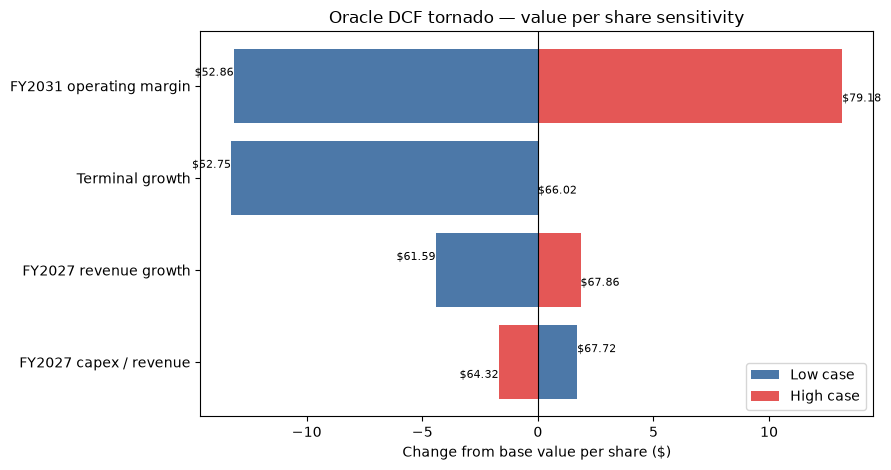

In [9]:
# Chart uses the existing calculated tornado results only; it does not alter ranges or inputs.
import matplotlib.pyplot as plt

chart = tornado.sort_values('Swing', ascending=True).copy()
base_value = v['per_share']
low_delta = chart['Low value / share'] - base_value
high_delta = chart['High value / share'] - base_value
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(chart['Driver'], low_delta, color='#4C78A8', label='Low case')
ax.barh(chart['Driver'], high_delta, color='#E45756', label='High case')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Oracle DCF tornado — value per share sensitivity')
ax.set_xlabel('Change from base value per share ($)')
ax.legend(loc='lower right')
for y, (low, high) in enumerate(zip(chart['Low value / share'], chart['High value / share'])):
    ax.text(low - base_value, y + 0.14, f'${low:,.2f}', ha='right' if low < base_value else 'left', va='center', fontsize=8)
    ax.text(high - base_value, y - 0.14, f'${high:,.2f}', ha='right' if high < base_value else 'left', va='center', fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## 8. Bridge, comparison with the dated WRDS price, and final judgment

The dated market comparison uses the $137.79 WRDS Compustat Security Daily price on 29 September 2026. The bridge reports all stale-output replacement measures: WACC, terminal-value share, implied EV/FY2027 EBIT, enterprise value, equity value, and value per share.

In [10]:
bridge = pd.DataFrame({'Measure':['Final WRDS beta','Cost of equity','WACC','PV of explicit FCFF','PV of terminal value','Terminal value / EV','Enterprise value','Less: net debt','Equity value','Shares (m)','Value / share','Dated WRDS price','Difference vs price','Implied EV / FY2027 EBIT'],
                       'Value':[WRDS_BETA,v['cost_of_equity'],v['wacc'],v['pv_fcff'],v['pv_tv'],v['tv_share'],v['ev'],-opening['net_debt'],v['equity_value'],opening['shares'],v['per_share'],MANUAL['price'],v['per_share']/MANUAL['price']-1,v['implied_ev_ebit']]})
display(bridge)
print('My base case assumes strong OCI growth but slower cash-flow conversion and margin realisation than the market appears to expect. The market price implies a faster or more profitable payback from Oracle’s data-centre investment than my base case supports.')

,Measure,Value
0,Final WRDS beta,1.64
1,Cost of equity,0.12
2,WACC,0.10
3,PV of explicit FCFF,"-2,016.35"
4,PV of terminal value,"299,886.05"
5,Terminal value / EV,1.01
6,Enterprise value,"297,869.70"
7,Less: net debt,"-98,252.00"
8,Equity value,"199,617.70"
9,Shares (m),"3,023.74"


My base case assumes strong OCI growth but slower cash-flow conversion and margin realisation than the market appears to expect. The market price implies a faster or more profitable payback from Oracle’s data-centre investment than my base case supports.


## 9. Full pro-forma exhibit and impossible-input check

This exhibit is generated from the same base-case forecast used above. The check table repeats for every forecast year immediately below the balance sheet and cash-flow schedules.

In [11]:
p=projection
income = pd.DataFrame({'Revenue':p.revenue,'EBIT':p.ebit,'Interest':p.interest,'Pretax income':p.pretax_income,'Taxes':p.taxes,'Net income':p.net_income}).T
balance = pd.DataFrame({'Cash (calculated last)':p.cash,'Accounts receivable':p.ar,'Inventory':p.inventory,'Other operating assets':p.other_operating_assets,'PP&E':p.ppe,'Total assets':p.assets,'Accounts payable':p.ap,'Debt':p.debt,'Total liabilities':p.liabilities,'Equity (roll-forward)':p.equity}).T
cashflow = pd.DataFrame({'Net income':p.net_income,'D&A':p.da,'Less: change in NWC':-p.delta_nwc,'Less: capex':-p.capex,'Less: dividends':-p.dividends,'Incremental borrowing':p.incremental_borrowing,'Ending cash':p.cash,'FCFF':p.fcff}).T
display(income.style.format('{:,.1f}')); display(balance.style.format('{:,.1f}')); display(cashflow.style.format('{:,.1f}')); display(forecast_checks.style.format('{:,.2f}'))
try:
    bad=deepcopy(MANUAL); bad['terminal_growth']=v['wacc']; value(company,BASE,bad)
except ValueError as exc: print('EXPECTED IMPOSSIBLE-INPUT FAILURE:', exc)

year,2027,2028,2029,2030,2031
Revenue,"80,828.4","95,377.5","110,637.9","121,701.7","130,220.8"
EBIT,"25,460.9","31,474.6","37,616.9","41,987.1","45,577.3"
Interest,"5,829.3","6,641.4","7,786.8","8,271.0","8,271.0"
Pretax income,"19,631.6","24,833.2","29,830.1","33,716.1","37,306.3"
Taxes,"4,319.0","5,463.3","6,562.6","7,417.5","8,207.4"
Net income,"15,312.6","19,369.9","23,267.5","26,298.6","29,098.9"


year,2027,2028,2029,2030,2031
Cash (calculated last),"10,000.0","10,000.0","10,000.0","16,200.9","33,133.2"
Accounts receivable,"12,462.0","14,705.2","17,058.0","18,763.8","20,077.2"
Inventory,363.6,429.0,497.7,547.5,585.8
Other operating assets,"49,310.4","58,186.3","67,496.1","74,245.7","79,442.9"
PP&E,"141,543.3","171,354.0","188,691.8","193,671.8","191,366.1"
Total assets,"213,679.3","254,674.5","283,743.5","303,429.6","324,605.2"
Accounts payable,"13,172.4","15,543.4","18,030.4","19,833.4","21,221.8"
Debt,"147,586.3","173,038.9","183,799.1","183,799.1","183,799.1"
Total liabilities,"160,758.7","188,582.4","201,829.5","203,632.5","205,020.9"
Equity (roll-forward),"52,920.6","66,092.1","81,914.0","99,797.1","119,584.3"


year,2027,2028,2029,2030,2031
Net income,"15,312.6","19,369.9","23,267.5","26,298.6","29,098.9"
D&A,"14,993.5","22,646.9","29,130.2","33,964.5","34,860.9"
Less: change in NWC,"-8,160.6","-8,813.4","-9,244.3","-6,702.1","-5,160.6"
Less: capex,"-56,579.9","-52,457.6","-46,467.9","-38,944.5","-32,555.2"
Less: dividends,"-4,900.0","-6,198.4","-7,445.6","-8,415.5","-9,311.7"
Incremental borrowing,"18,045.3","25,452.6","10,760.2",0.0,0.0
Ending cash,"10,000.0","10,000.0","10,000.0","16,200.9","33,133.2"
FCFF,"-29,887.4","-14,074.0","2,759.1","21,067.8","32,695.4"


,Balance identity: assets − liabilities − equity,Cash-flow tie,Cash-floor check: cash − floor,PASS
year,,,,
2027,0.00,0.00,0.00,1.00
2028,0.00,0.00,0.00,1.00
2029,0.00,0.00,0.00,1.00
2030,-0.00,0.00,"6,200.87",1.00
2031,0.00,0.00,"23,133.22",1.00


EXPECTED IMPOSSIBLE-INPUT FAILURE: VALUATION REFUSED: terminal growth must be below WACC.


## 10. Honest range versus dated market price

The low/base/high scenarios produce a per-share valuation range of **$48.74–$83.67**, with a base-case value of **$66.02**. This is compared with Oracle’s **$137.79** closing price on **29 September 2026**, pulled from **WRDS Compustat Security Daily**, which is within one week of submission. Even the high scenario remains below the dated market price, so this is an honest assumption-sensitive range rather than a precise price target.

**FY2031 operating margin is the single assumption most likely to move the valuation.** In the tornado, its low and high cases produce values of **$52.86** and **$79.18** per share, respectively. For the high end to be justified, Oracle would need sustained OCI/AI demand and capacity utilisation sufficient for operating leverage to overcome the cost and depreciation burden of its new data-centre footprint.